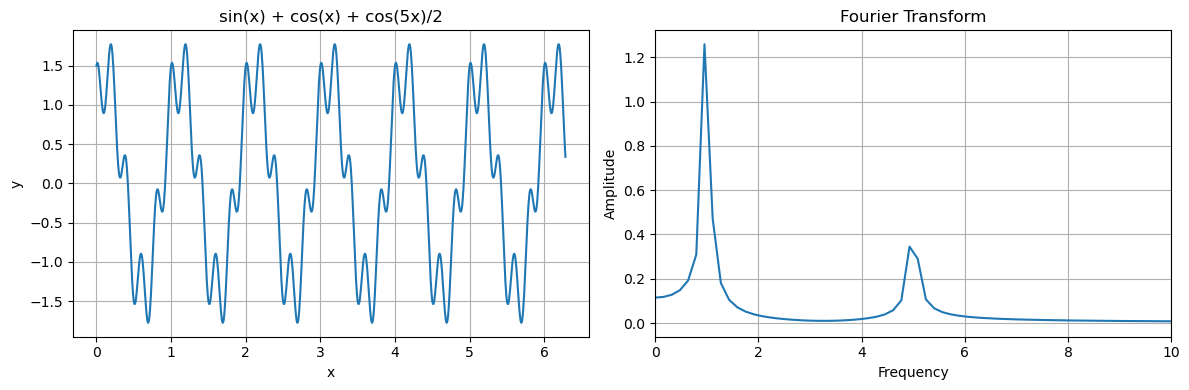

In [8]:
import numpy as np
from scipy.fft import fft, fftfreq

import matplotlib.pyplot as plt

# Define the function
x = np.linspace(0, 2 * np.pi, 1000)
y = np.sin(2 * np.pi * x) + np.cos(2 * np.pi * x) + np.cos(2 * np.pi * 5 * x) / 2

# Compute FFT
N = len(y)
yf = fft(y)
xf = fftfreq(N, x[1] - x[0])[: N // 2]

# Plot original function
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(x, y)
plt.xlabel("x")
plt.ylabel("y")
plt.title("sin(x) + cos(x) + cos(5x)/2")
plt.grid()

# Plot frequency spectrum
plt.subplot(1, 2, 2)
plt.xlim(right=10)
plt.plot(xf, 2.0 / N * np.abs(yf[: N // 2]))
plt.xlabel("Frequency")
plt.ylabel("Amplitude")
plt.title("Fourier Transform")
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
explanation = """
The FFT x-axis (xf from fftfreq) is in cycles per unit of x (Hz), not in radians. 
Your waveforms use angular frequencies ω: sin(x) has ω=1 rad/unit and cos(5x) has ω=5 rad/unit.
To convert to cycles/unit (what xf shows) use f = ω / (2π), so the peaks appear near 1/(2π) ≈ 0.159 and 5/(2π) ≈ 0.796, not at 1 and 5.

If you want peaks at 1 and 5, either:
- define the signals as sin(2π*1*x) and cos(2π*5*x) (use cycles directly), or
- plot angular frequency ω = 2π * xf on the x-axis.

Also note xf depends on the sample spacing x[1]-x[0], which sets the frequency scaling and resolution.
"""

print(explanation)

In [ ]:
explanation_peaks = """
The FFT produces amplitudes on a discrete frequency grid with spacing df = 1 / T,
where T = x[-1] - x[0] is the total sampled duration. If a true frequency does not
fall exactly on one of these bins (i.e. the number of cycles in the record is not an
integer), its energy spreads into neighboring bins (spectral leakage) and the
measured peak will not sit exactly at the theoretical value (1 or 5).

Other contributors: finite record length (limits frequency resolution), the implicit
boxcar window (causes leakage and sidelobes), and discrete sampling/rounding of bin
indices. Remedies: increase T (denser frequency bins), zero-pad or interpolate the FFT,
use a window function to control leakage, or choose T so that f*T is an integer.
"""

print(explanation_peaks)